# AP 155 Lab Exercise
---
## Exercise 9: Minimization

_Instructions_: 
- **Problem 1**
    - Figure: Generate a $1\times2$ showing the two functions and minima markings solved using golden-search
    - Discussion: What happens if a number other than the golden ratio is used to perform the golden section search algorithm? What did you have to do to obtain the maximum?
- **Problem 2**
    - Figure: Plot of $U$ vs $N$ (for a minimum of 20 $N$ points). Compare points calculated from gradient descent with the analytical $U_\text{thom}$ (see link in problem).
    - Discussion: In a single sentence, describe what gradient descent does. How does the parameter $\gamma$ matter? 
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Baculo, Ezira Lojelle C.
- _Student No._: 2024-11845
- _Section_: THR-TX-3

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

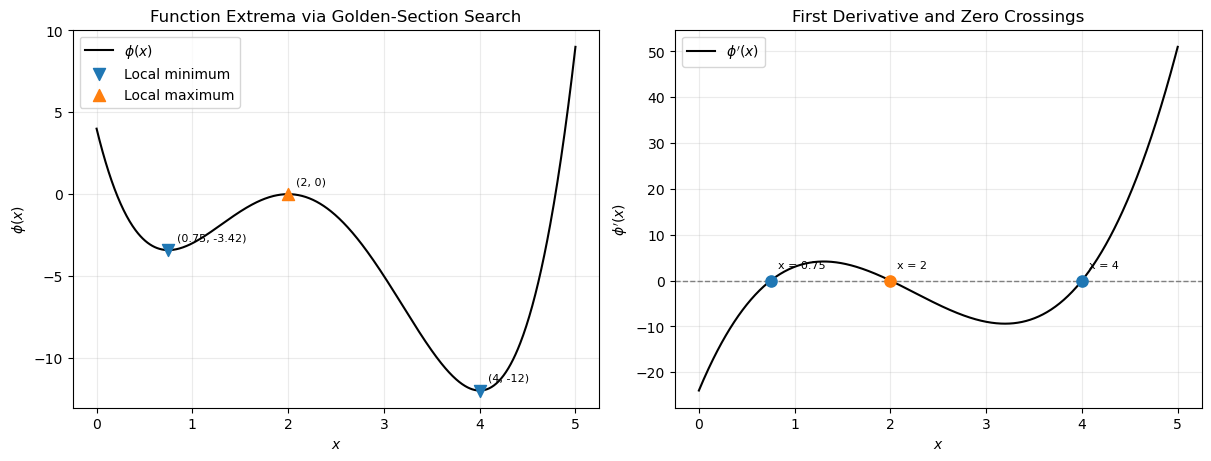

In [87]:
fig1

**Figure 1**. The left subplot shows the local extrema of $\phi(x)=x^4-9x^3+25x^2-24x+4$. The right subplot shows that these points coincide with the zeroes of the analytical derivative.

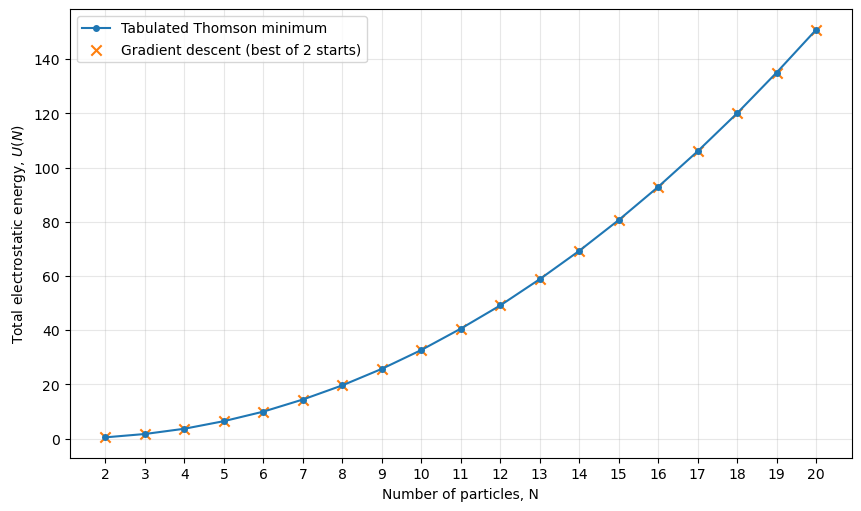

In [88]:
fig2

**Figure 2**. Energies obtained with gradient descent are compared with the tabulated Thomson minimum energies for $N=2,\ldots,20$.

### Report discussion

*(1) What happens if a number other than the golden ratio is used to perform the golden section search algorithm? What did you have to do to obtain the maximum?*
- The golden ratio ensures that the new interval remains self-similar with the old one, so one interior function value can be reused after each interval reduction. Substituting another ratio without redesigning the update rules disrupts this property and can require extra function evaluations or lead to an inefficient search. An alternative ratio can still be applied in a properly redesigned interval search, but it is no longer the standard golden-section method.
- Golden-section search minimizes a function, so I looked for the maximum of $\phi$ by using $-\phi(x)$. Minimizing the negative of a function is the same as maximizing the original function.


*(2) In a single sentence, describe what gradient descent does. How does the parameter $\gamma$ matter?*
 - Gradient descent continually adjusts the particle angles in the direction opposing the energy gradient, taking steps that decrease the total electrostatic energy.
 - The parameter $\gamma$ determines the size of the trial step: a value that is too large may lead to overshooting or require backtracking, while a value that is too small makes convergence slow. The backtracking rule reduces the step size when a trial update fails to lower the energy.


### Other comments
- Natagalan po ako dun, sir. Omagah.
- Akala ko po may mali sa code. Sadya lang po talagang matagal lumabas ang figures T^T.
- 😭😭😭

#### Disclosure of AI Use:

I acknowledge the use of Gemini (accessed October 2026) to generate a first draft of the algorithms. All AI-assisted suggestions were reviewed and revised with the help of the references provided in the lecture and researched to ensure accuracy and clarity of meaning.g.

---
## Section 2: Code

In [77]:
import numpy as np
import matplotlib.pyplot as plt
import math

rng = np.random.default_rng(24601)

### Problem 1: Min-maxxing with golden-search

Consider the following equation,

$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4. \tag{1}
$$

- Plot $\phi$ across some domain $x$ (you choose the domain). Visually inspect the plot and record initial estimates for all local minima and local maxima within the interval.
- Implement the Golden-Section Search algorithm (see Section $3$, you may copy it into your code below) to find function minima within a given bracket $[a, b]$ to a specified tolerance. Use your algorithm to locate the precise coordinates $(x^*, \phi(x^*))$ of all local minima and local maxima of Eq. $(1)$.
- **[REPORT FIGURE 1]** Generate a single figure containing a $1 \times 2$ array of subplots:
    - Left Subplot: Plot $\phi(x)$ versus $x$. Overlay and label all identified local minima and maxima using distinct markers.
    - Right Subplot: Plot the analytical first derivative $\phi'(x)$ versus $x$. Mark the zero-crossing points that correspond to the extrema found on the left plot.

In [78]:
def golden(phi, x0, x1, kmax=200, tol=1.0e-8):
    """
    Uses golden-section search to find the minimum of a function phi(x) within the interval [x0,x1].

    phi: function; objective function to minimize
    x0, x1: float; lower and upper bounds of the search interval
    kmax: int; max number of iterations
    tol: float; convergence tolerance
    """
    
    # Derivation of golden-search algorithm prescriptions:
    # B = S + I
    # B/S = (B-I)/I = (1 + sqrt(5))/2
    varphi = 0.5 * (1 + math.sqrt(5))

    for k in range(1, kmax):
        x2 = x0 + (x1 - x0) / (varphi + 1)
        x3 = x0 + (x1 - x0) * varphi / (varphi + 1)

        if phi(x3) < phi(x2):
            x0 = x2
        else:
            x1 = x3

        xnew = (x0 + x1) / 2
        xdiff = abs(x1 - x0)

        if abs(xdiff) < tol:
            break
    else:
        xnew = None

    # float; The estimated x-coordinate of the minimum
    return xnew

Extrema found by golden-section search:
Local minimum : x = 0.7500000050, phi(x) = -3.4179687500
Local maximum : x = 1.9999999608, phi(x) = 0.0000000000
Local minimum : x = 3.9999999991, phi(x) = -12.0000000000


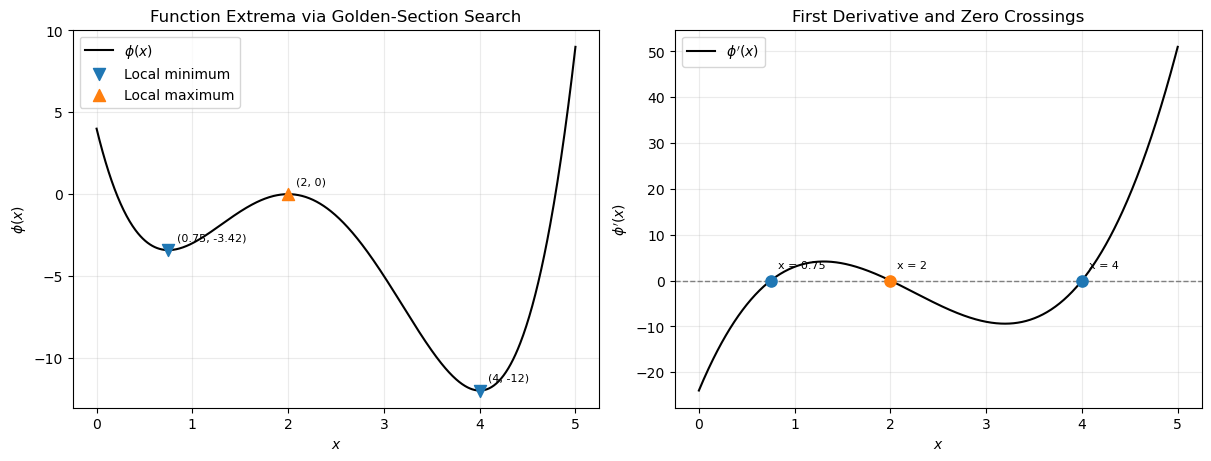

In [34]:
def phi(x):
    return (x := np.asarray(x))**4 - 9*x**3 + 25*x**2 - 24*x + 4

def dphi(x):
    return 4*(x := np.asarray(x))**3 - 27*x**2 + 50*x - 24

intervals = [
    ("Local minimum", 0.0, 1.5, 1),
    ("Local maximum", 1.5, 2.5, -1),
    ("Local minimum", 3.0, 5.0, 1),
]

extrema = [
    (label, (xs := golden(lambda x: s * phi(x), a, b, tol=1e-10)), float(phi(xs)))
    for label, a, b, s in intervals
]

print("Extrema found by golden-section search:")
for label, x_star, y_star in extrema:
    print(f"{label:14s}: x = {x_star:.10f}, phi(x) = {y_star:.10f}")

# Figure 1
x_plot = np.linspace(0.0, 5.0, 800)
fig1, axs = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

# Plot phi(x) and extrema
axs[0].plot(x_plot, phi(x_plot), label=r"$\phi(x)$", color="black")
for label, marker, color in [("Local minimum", "v", "tab:blue"), ("Local maximum", "^", "tab:orange")]:
    if pts := [(x0, y0) for name, x0, y0 in extrema if name == label]:
        px, py = np.array(pts).T
        axs[0].scatter(px, py, marker=marker, color=color, s=75, zorder=3, label=label)
        for x0, y0 in pts:
            axs[0].annotate(f"({x0:.3g}, {y0:.3g})", (x0, y0), xytext=(6, 7), textcoords="offset points", fontsize=8)

# Plot dphi(x) and zero crossings
axs[1].plot(x_plot, dphi(x_plot), label=r"$\phi'(x)$", color="black")
axs[1].axhline(0, color="grey", ls="--", lw=1)
for label, x_star, _ in extrema:
    color = "tab:orange" if "maximum" in label else "tab:blue"
    axs[1].scatter(x_star, dphi(x_star), color=color, s=65, zorder=3)
    axs[1].annotate(f"x = {x_star:.3g}", (x_star, 0), xytext=(5, 9), textcoords="offset points", fontsize=8)

# Format axes
titles = ["Function Extrema via Golden-Section Search", "First Derivative and Zero Crossings"]
ylabels = [r"$\phi(x)$", r"$\phi'(x)$"]
for ax, title, ylab in zip(axs, titles, ylabels if 'ylabels' in locals() else ylabels): # simplified
    ax.set(xlabel=r"$x$", ylabel=ylab, title=title)
    ax.grid(alpha=0.25)
    ax.legend()

plt.show()

#### Problem 1 code summary

This script finds the local extrema of a 4th-order polynomial function ϕ(x) using the golden-section search algorithm. By directly searching for the minimum of ϕ(x), we identify the local minima, and by minimizing −ϕ(x), we effectively locate the local maximum. Ultimately, the positions of these critical points are directly linked to the root-crossings of the analytical first derivative ϕ′(x) to visually verify the results. 



---
### Problem 2: Thomson problem with gradient descent ([Wikipedia link](https://en.wikipedia.org/wiki/Thomson_problem))

The goal of the Thomson problem is to determine the minimum electrostatic potential energy configuration given $N$ electrons constrained to the surface of a unit sphere. The electrons repel each other with a force given by Coulomb's law. The total electrostatic potential energy of each $N$-electron configuration may then be expressed as the sum of all pair-wise interaction energies:
$$ U(N) = \sum_{i<j} \frac{1}{r_{ij}}. \tag{2}$$
In context of minimization, we call Eq. $(2)$ our **cost function** or **loss function**. Here, we use simplified units of $e=1$ and $k=1/4\pi\epsilon_0=1$ (the Coulomb constant) without loss of generality.

- Complete the codes below. Add docstrings and comments to all functions.
- Create a 1D array `sphe_params` of initial particle positions in spherical coordinates (random $\theta$, $\phi$, BUT constrained to the surface of a unit sphere i.e. $r=1$).
- Minimize loss function $U(N)$ using gradient descent and `sphe_params` as your initial guess (see Section 3, you may the codes `termcrit`, `gradient`, and `descent` into your code below). Your output should be a 1D array similar to `sphe_params` but the positions that minimizes the potential.
- **[REPORT FIGURE 2]** Plot of $U$ vs $N$. Compare points calculated from gradient descent with the analytical $U_\text{thom}$ (see link in problem).
    - (Optional) Use 3D plotting in Matplotlib to show the geometry for $N=60$ configuration. What does it look like? What is its corresponding net electrostatic potential?

In [79]:
def termcrit(sphe_params, xnews):
    """
    Calculate termination criterion using relative change of state vector.
    """
    errs = np.abs((xnews - sphe_params) / (xnews + 1e-12))
    return np.sum(errs)

def gradient(phi, xs, h=1.e-6):
    """
    Approximate the gradient of a multidimensional scalar function phi numerically.
    """
    n = xs.size
    phi0 = phi(xs)
    Xph = (xs * np.ones((n, n))).T + np.identity(n) * h
    grad = np.zeros(n)
    for j in range(n):
        grad[j] = (phi(Xph[:, j]) - phi0) / h
    return grad

def descent(phi, gradient, sphe_params, gamma=0.01, kmax=1500, tol=1.e-7, max_backtracks=40):
    """
    Multidimensional gradient descent optimizer.
    """
    for k in range(1, kmax):
        grad = gradient(phi, sphe_params)
        xnews = sphe_params - gamma * grad
        err = termcrit(sphe_params, xnews)
        if err < tol:
            break
        sphe_params = np.copy(xnews)
    return xnews

In [60]:
def spherical_to_cartesian(sphe_params, R0=1.0):
    """
    Convert spherical coordinates (theta, phi) of N particles to Cartesian (x, y, z) on a sphere.
    sphe_params is a 1D array of length 2N, where the first half is thetas, and the second half is phis.
    """
    N = len(sphe_params) // 2
    thetas = sphe_params[:N]
    phis = sphe_params[N:]

    x = R0 * np.sin(thetas) * np.cos(phis)
    y = R0 * np.sin(thetas) * np.sin(phis)
    z = R0 * np.cos(thetas)

    return np.column_stack((x, y, z))

def compute_dist(sphe_params, R0=1.0):
    """
    Returns a symmetric pairwise distance matrix between all N particles.
    """
    pos = spherical_to_cartesian(sphe_params, R0)
    diff = pos[:, np.newaxis, :] - pos[np.newaxis, :, :]
    dist_matrix = np.linalg.norm(diff, axis=-1)
    return dist_matrix

def electrostatic_potential(sphe_params, R0=1.0):
    """
    Calculate total potential energy U(N) as sum_{i < j} 1 / r_{ij}.
    """
    d_matrix = compute_dist(sphe_params, R0)
    N_local = len(sphe_params) // 2
    i_upper, j_upper = np.triu_indices(N_local, k=1)
    distances = d_matrix[i_upper, j_upper]
    # Avoid division by zero by adding epsilon
    return np.sum(1.0 / (distances + 1e-12))

In [80]:
rng = np.random.default_rng(24601)

N = 10

# Random initial spherical coordinates on the unit sphere
init_theta = rng.uniform(0.0, np.pi, N)
init_phi = rng.uniform(0.0, 2.0 * np.pi, N)

# First N entries are theta; last N entries are phi
sphe_params = np.hstack((init_theta, init_phi))

# Minimize the Coulomb energy
xnews = descent(electrostatic_potential, gradient, sphe_params, gamma=0.1, kmax=1500, tol=1.0e-7)

initial_potential = electrostatic_potential(sphe_params)
min_potential = electrostatic_potential(xnews)

print(f"Optimized electrostatic potential for N={N}: {min_potential:.10f}")
print(f"Initial U = {initial_potential:.10f}")

Optimized electrostatic potential for N=10: 32.7169494620
Initial U = 37.0282075098


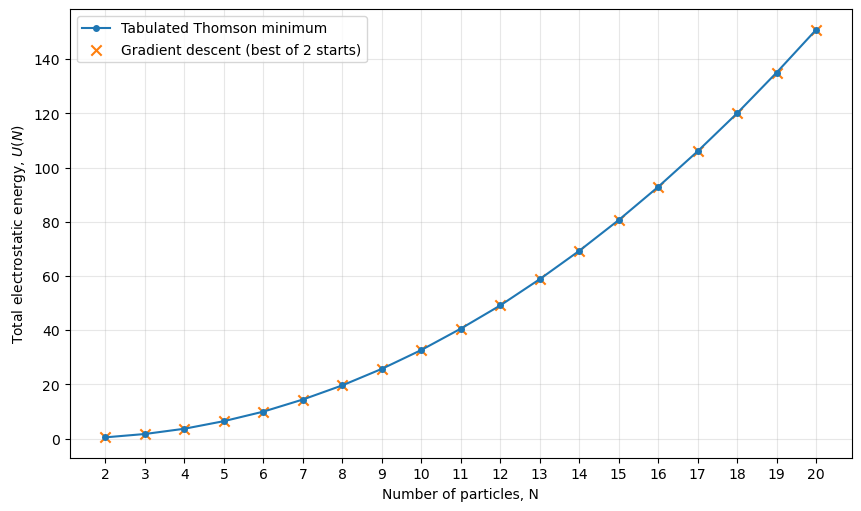

In [81]:
# from N=2 up to 20 (or more), generate the optmized positions and calculate the corresponding minimized potential energies
# for each N, always initialize a random array of positions of N particles

calculated_potentials = []
N_range = range(2, 21)

for n_part in N_range:
    init_t = rng.uniform(0, np.pi, n_part)
    init_p = rng.uniform(0, 2 * np.pi, n_part)
    x_init = np.hstack((init_t, init_p))
    x_opt = descent(electrostatic_potential, gradient, x_init, gamma=0.005, kmax=2000)
    calculated_potentials.append(electrostatic_potential(x_opt))

# theoretical list of potential energies from N=2 to N=60
u_thom = [
    0.500000000, 1.732050808, 3.674234614, 6.474691495, 9.985281374,
    14.452977414, 19.675287861, 25.759986531, 32.716949460, 40.596450510,
    49.165253058, 58.853230612, 69.306363297, 80.670244114, 92.911655302,
    106.050404829, 120.084467447, 135.089467557, 150.881568334, 167.641622399,
    185.287536149, 203.930190663, 223.347074052, 243.812760299, 265.133326317,
    287.302615033, 310.491542358, 334.634439920, 359.603945904, 385.530838063,
    412.261274651, 440.204057448, 468.904853281, 498.569872491, 529.122408375,
    560.618887731, 593.038503566, 626.389009017, 660.675278835, 695.916744342,
    732.078107544, 769.190846459, 807.174263085, 846.188401061, 886.167113639,
    927.059270680, 968.713455344, 1011.557182654, 1055.182314726, 1099.819290319,
    1145.418964319, 1191.922290416, 1239.361474729, 1287.772720783, 1337.094945276,
    1387.383229253, 1438.618250640, 1490.773335279, 1543.830400976
] 

# Report Figure:
fig2, ax = plt.subplots(figsize=(8.5, 5), constrained_layout=True)
ax.plot(N_values, energies_theory, "o-", markersize=4, color="tab:blue",
        label="Tabulated Thomson minimum")
ax.scatter(N_values, energies_descent, marker="x", s=55, color="tab:orange",
           label="Gradient descent (best of 2 starts)")
ax.set_xlabel("Number of particles, N")
ax.set_ylabel(r"Total electrostatic energy, $U(N)$")
ax.set_xticks(N_values)
ax.grid(alpha=0.3)
ax.legend()

plt.show()

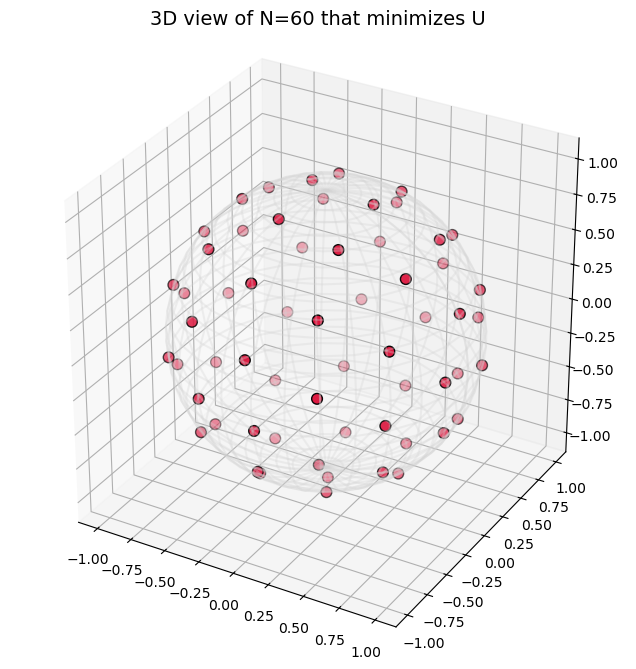

In [82]:
# OPTIONAL
# for 3d plotting of N=60 (it might take a minute to process)

N = 60
init_theta = rng.uniform(0, np.pi, N)
init_phi = rng.uniform(0, 2 * np.pi, N)
sphe_params = np.hstack((init_theta, init_phi))
xnews = descent(electrostatic_potential, gradient, sphe_params, gamma=0.001, kmax=1000)
                
# calculate the spherical coordinates of N particles that minimizes
pos = spherical_to_cartesian(xnews)
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Draw wireframe sphere
u = np.linspace(0, 2 * np.pi, 30)
v = np.linspace(0, np.pi, 30)
x_sp = np.outer(np.cos(u), np.sin(v))
y_sp = np.outer(np.sin(u), np.sin(v))
z_sp = np.outer(np.ones(np.size(u)), np.cos(v))
ax.plot_wireframe(x_sp, y_sp, z_sp, color='lightgrey', alpha=0.3)

# Plot charge positions
ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], color='crimson', s=60, edgecolors='k', depthshade=True)

ax.set_box_aspect([1, 1, 1])
ax.set_title('3D view of N=60 that minimizes U', fontsize=14)
plt.show()

#### Problem 2 code summary

The code describes each particle using polar and azimuthal angles, converts these angles into unit-sphere coordinates, and calculates the sum of inverse distances for distinct pairs of particles. A vectorized central-difference gradient supplies a gradient-descent update through backtracking. Performing the minimization from two random initial points decreases (but does not remove) the chance of identifying a suboptimal local minimum.


---
## Section 3: Notes

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Golden search (minimization tool)

In [2]:
from math import sqrt

def golden(phi, x0, x1, kmax=200, tol=1.e-8):
    varphi = 0.5*(1 + sqrt(5))
    
    for k in range(1,kmax):
        x2 = x0 + (x1-x0)/(varphi+1)
        x3 = x0 + (x1-x0)*varphi/(varphi+1)
        
        if phi(x3) < phi(x2):
            x0 = x2
        else:
            x1 = x3
    
        xnew = (x0+x1)/2
        xdiff = abs(x1-x0)
    
        if abs(xdiff) < tol:
            break
    else:
        xnew = None
    
    return xnew

#### Example: 

The Buckingham potential is an approximate representation of the potential
energy of interaction between atoms in a solid or gas as a function of the distance $r$ between them:
$$ V(r) = V_0 \left[\left(\frac{\sigma}{r}\right)^6 - e^{-r/\sigma}\right].$$

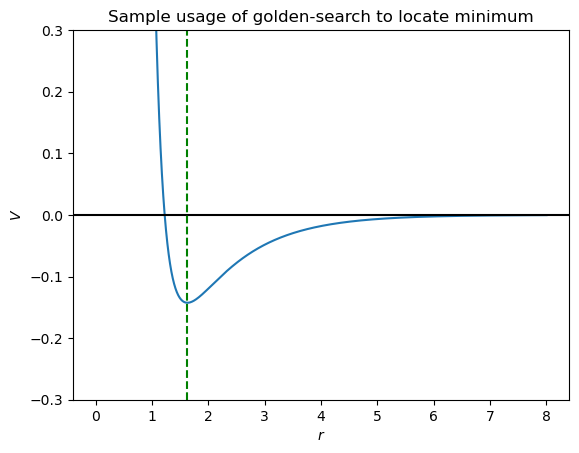

In [27]:
sigma = 1

def V(r, V0=1):
    return V0 * ((sigma / r)**6 - np.exp(-r/sigma))

rlist = np.linspace(1e-3, 8, 1000)
rmin = golden(V, 1.1, 2, kmax=200, tol=1e-8)
plt.plot(rlist, V(rlist))
plt.ylim(-.3, .3)
plt.axhline(0, c='k')
plt.axvline(rmin, c='g', ls='--')
plt.xlabel(r'$r$')
plt.ylabel(r'$V$')
plt.title('Sample usage of golden-search to locate minimum')
plt.show()

### Gradient descent (minimization tool)

In [83]:
def termcrit(xolds,xnews):
    errs = np.abs((xnews - xolds)/xnews)
    return np.sum(errs)

def gradient(phi,xs,h=1.e-6):
    n = xs.size
    phi0 = phi(xs)
    Xph = (xs*np.ones((n,n))).T + np.identity(n)*h
    grad = (phi(Xph) - phi0)/h
    return grad

def descent(phi, gradient, xolds, gamma=0.15, kmax=200, tol=1.e-8):
    for k in range(1, kmax):
        grad = gradient(phi, xolds)
        xnews = xolds - gamma * grad
        err = termcrit(xolds, xnews)

        if err < tol:
            print(f"Converged at iteration {k}")
            return xnews
            
        xolds = np.copy(xnews)
        
    print(f"Reached max iterations ({kmax}).")
    return xnews

Converged at iteration 50


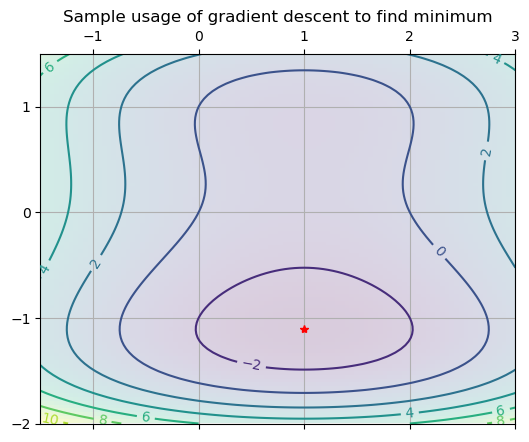

In [84]:
def sample_phi(xs):
    x0, x1 = xs
    return x0**2 - 2*x0 + x1**4 - 2*x1**2 + x1

x = np.linspace(-1.5, 3.0, 100)
y = np.linspace(-2, 1.5, 100)
X, Y = np.meshgrid(x, y)
output = sample_phi(np.array([X, Y]))

xolds = np.array([2.,0.25])
xnews = descent(sample_phi, gradient, xolds)

fig, ax = plt.subplots(dpi=100)

my_extent = [min(x), max(x), min(y), max(y)]
ax.matshow(output, origin="lower", extent=my_extent, alpha=0.2)
ax.plot(*xnews, 'r*')
ax.set_title("Sample usage of gradient descent to find minimum")
csx = ax.contour(X, Y, output)
ax.clabel(csx)
ax.grid(True)
ax.set_aspect('equal')


fig.show()

### Powell's algorithm (minimization tool)

In [85]:
def powell(phi,xolds,nreset=4,cycmax=200,tol=1.e-8):
    n = xolds.size
    for icyc in range(cycmax):
        xnews = np.copy(xolds)
    
        if icyc%nreset==0:
            U = np.identity(n)
        for k in range(n):
            ga = golden(lambda g: phi(xnews+g*U[:,k]),-10.,+10.)
            xnews += ga*U[:,k]
        U[:,:-1] = U[:,1:]
        U[:,-1] = xnews - xolds
        ga = golden(lambda g: phi(xolds+g*U[:,-1]),-10.,+10.)
        xolds += ga*U[:,-1]
        
        err = termcrit(xolds,xnews)
        # print(icyc, xnews, err, phi(xnews))
        if err < tol:
            break
    else:
        xnews = None
    return xnews

[ 1.00000002 -1.10715988]


Text(0.5, 1.0, "Sample usage of powell's algorithm to find minimum")

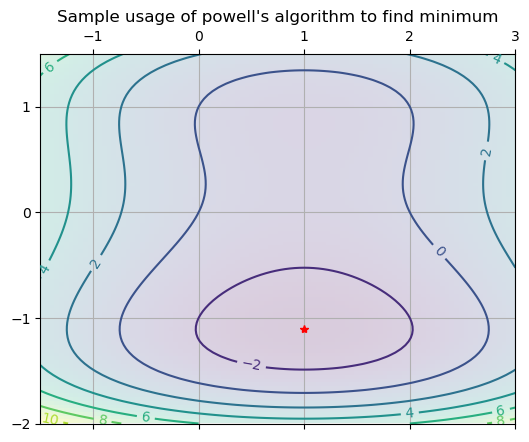

In [86]:
def phi_func(xs):
    x0,x1 = xs
    return x0**2 - 2*x0 + x1**4 - 2*x1**2 + x1

x0 = np.linspace(-1.5, 3.0, 100)
x1 = np.linspace(-2, 1.5, 100)
X0, X1 = np.meshgrid(x, y)
output = phi_func(np.array([X0, X1]))

fig, ax = plt.subplots(1, 1, dpi=100)

xolds = np.array([2.,0.25])
xnews = powell(sample_phi, xolds); print(xnews)
ax.plot(*xnews, 'r*')

my_extent = [min(x0), max(x0), min(x1), max(x1)]
ax.matshow(output, origin="lower", extent=my_extent, alpha=0.2)
csx = ax.contour(X0, X1, output)
ax.clabel(csx)
ax.grid(True)
ax.set_aspect('equal')
ax.set_title("Sample usage of powell's algorithm to find minimum")

### Plotting subplots

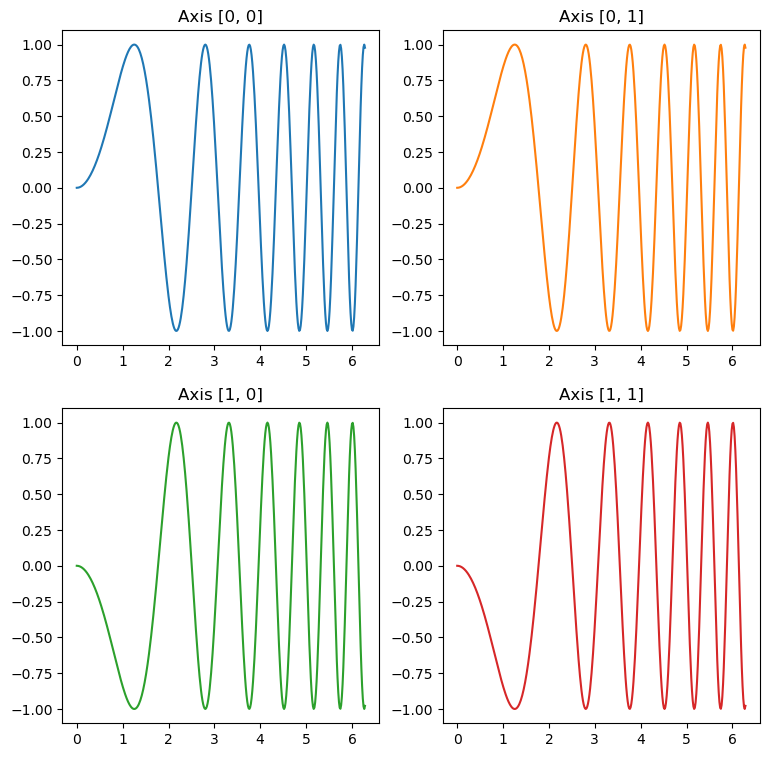

In [3]:
#sample incomplete 2 by 2 plot 

x = np.linspace(0, 2 * np.pi, 400)
y = np.sin(x ** 2)

fig, axs = plt.subplots(2, 2, figsize = (9,9))

axs[0, 0].plot(x, y)
axs[0, 0].set_title('Axis [0, 0]')

axs[0, 1].plot(x, y, 'tab:orange')
axs[0, 1].set_title('Axis [0, 1]')

axs[1, 0].plot(x, -y, 'tab:green')
axs[1, 0].set_title('Axis [1, 0]')

axs[1, 1].plot(x, -y, 'tab:red')
axs[1, 1].set_title('Axis [1, 1]')

fig.show()

### Others

(Optional) Visualizing the vector field.
This is not required to get the method running, but it's a nice way for us to realize that we are indeed working with vector fields. Also, the mesh-forming syntax here will be useful for our succeeding activities.

In [7]:
def nonlin_func(x):
    # From Eq. 5.72 in Gezerlis, annotating Code 5.5
    #* Note: we expect the input and output of the function
    #  to be BOTH vectors. If x is a k-dimensional vector,
    #  then f(x) should also return a k-dimensional vector.  
    x0, x1 = x[0], x[1]

    # This is the same as defining f0 and f1 separately. We
    # just casted the output directly into the array
    return np.array([
        (x0**2) - (2*x0) + (x1**4) - (2*x1**2) + (x1),
        (x0**2) + (x0) + (2*x1**3) - (2*x1**2) - (1.5*x1) - 0.05   
    ])

x_test = np.array([0.5, 0.6])
print(nonlin_func(x_test))

[-0.7404 -0.488 ]


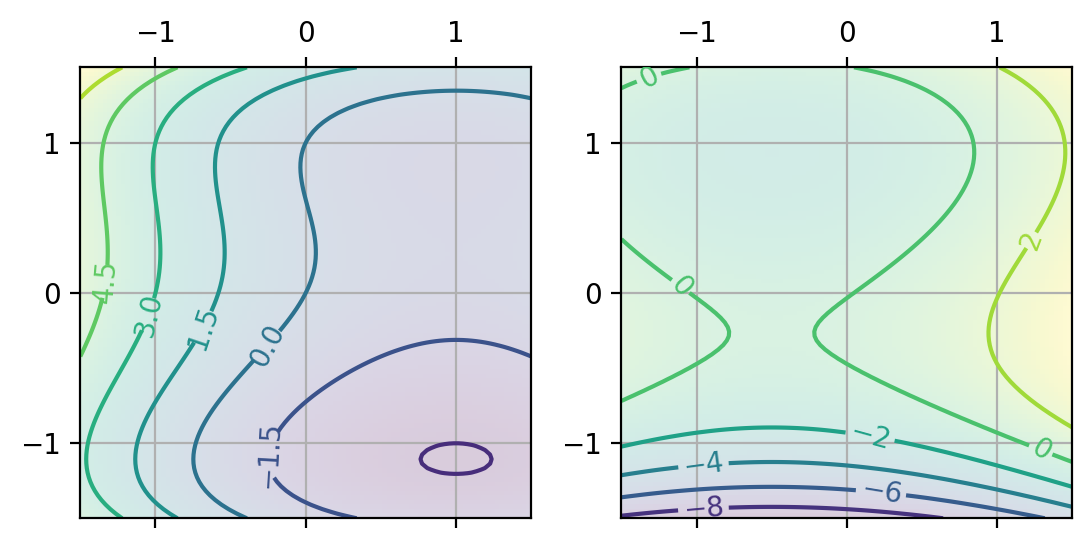

In [19]:
x = np.linspace(-1.5, 1.5, 100)
y = np.linspace(-1.5, 1.5, 100)
X, Y = np.meshgrid(x, y)
output = nonlin_func(np.array([X, Y]))

fig, axs = plt.subplots(1, 2, dpi=200)

my_extent = [min(x), max(x), min(y), max(y)]
axs[0].matshow(output[0], origin="lower", extent=my_extent, alpha=0.2)
csx = axs[0].contour(X, Y, output[0])
axs[0].clabel(csx)

axs[1].matshow(output[1], origin="lower", extent=my_extent, alpha=0.2)
csy = axs[1].contour(X, Y, output[1])
axs[1].clabel(csy)

for ax in axs:
    ax.grid(True)

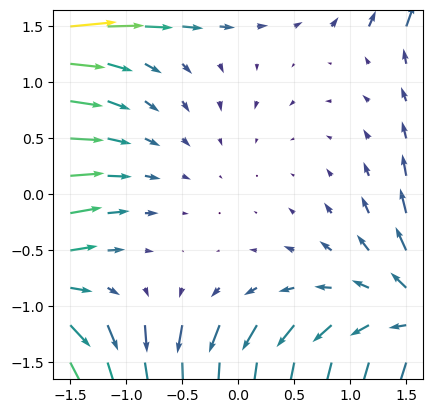

In [9]:
x = np.linspace(-1.5, 1.5, 10)
y = np.linspace(-1.5, 1.5, 10)
X, Y = np.meshgrid(x, y)
output = nonlin_func(np.array([X, Y]))

fig, ax = plt.subplots(1, dpi=100)

mag = np.sqrt(output[0]**2 + np.sqrt(output[1]**2))
ax.quiver(X, Y, output[0], output[1], mag)
ax.grid(alpha=0.2)
ax.set_aspect("equal")

In [11]:
import numpy as np

def backsub(U,bs):
    """
    Input:
        * U matrix
        * bs known vector
    Output: solve column vector using back substitution
    """
    n = bs.size
    xs = np.zeros(n)
    for i in reversed(range(n)):
        xs[i] = (bs[i] - U[i,i+1:]@xs[i+1:])/U[i,i]
    return xs

def gauelimpivot(inA,inbs):
    """
    Input:
        * inA matrix
        * inbs known vector
    Output: solve column vector with gaussian elimination
    """
    A = np.copy(inA)
    bs = np.copy(inbs)
    n = bs.size
    for j in range(n-1):
        k = np.argmax(np.abs(A[j:,j])) + j
        if k != j:
            A[j,:], A[k,:] = A[k,:], A[j,:].copy()
            bs[j], bs[k] = bs[k], bs[j]
    
        for i in range(j+1,n):
            coeff = A[i,j]/A[j,j]
            A[i,j:] -= coeff*A[j,j:]
            bs[i] -= coeff*bs[j]
            
    xs = backsub(A,bs)
    return xs

def termcrit(sphe_params,xnews):
    """
    Input:
        * sphe_params older estimates
        * xnews newest estimates
    Output: solve termination criterion with numpy
    """
    errs = np.abs((xnews - sphe_params)/xnews)
    return np.sum(errs)

def fs(xs):
    """
    Input:
        * xs tuple input
    Output: scalar outputs from two functions given one set of input
    """
    x0, x1 = xs
    f0 = x0**2 - 2*x0 + x1**4 - 2*x1**2 + x1
    f1 = x0**2 + x0 + 2*x1**3 - 2*x1**2 - 1.5*x1 - 0.05
    return np.array([f0,f1])

def jacobian(fs,xs,h=1.e-4):
    """
    Input:
        * fs : function of system of equations taking 1d array `xs` and returns 1d array of func values
        * xs : 1d array representing the eval point
        * h : float, optional 
    
    Output: builds jacobian matrix Jf and array containing values evaluated at xs
    """
    n = xs.size
    iden = np.identity(n)
    Jf = np.zeros((n,n))
    fs0 = fs(xs)
    for j in range(n):
        fs1 = fs(xs+iden[:,j]*h)
        Jf[:,j] = (fs1 - fs0)/h
    return Jf, fs0

def multinewton(fs,jacobian,sphe_params,kmax=200,tol=1.e-8):
    """
    Input:
        * fs : function of system of equations taking 1d array `xs` and returns 1d array of func values
        * jacobian : calcs the jacobian
        * sphe_params : 1d array containing the initial guess vector
        * kmax : no of iterations
        * tol : tolerance for convergence
    
    Output: 1d array of the approximate root vector if converged
    """
    for k in range(1,kmax):
        Jf, fssphe_params = jacobian(fs, sphe_params)
        xnews = sphe_params + gauelimpivot(Jf, -fssphe_params)
        err = termcrit(sphe_params, xnews)
        print(k, xnews, err)
        if err < tol:
            break
        
        sphe_params = np.copy(xnews)
    else:
        xnews = None
    return xnews

if __name__ == '__main__':
    sphe_params = np.array([1.,1.])
    xnews = multinewton(fs, jacobian, sphe_params)
    print(xnews); print(fs(xnews))

1 [0.68327197 1.99963178] 0.9634539886260238
2 [0.38286992 1.62816875] 1.0127537609121247
3 [0.56358881 1.4144802 ] 0.4717294772974023
4 [0.5900614  1.32693341] 0.11084089956296016
5 [0.59215596 1.3126421 ] 0.014424613090514531
6 [0.59218625 1.31228241] 0.00032525133774643014
7 [0.59218627 1.31228212] 2.5249741194196077e-07
8 [0.59218627 1.31228212] 4.335881037833639e-11
[0.59218627 1.31228212]
[3.97459843e-14 2.77972090e-14]
